# 0 Analizamos datos con Clusterizacion K-Menas

In [ ]:
# La clusterizacion nos ayuda a formar grupos de datos
# segun lo que nos interese

In [1]:
# 1.0 Cargamos los datos del archivo de Casas
import pandas as pd
datos = pd.read_csv("U4_01_housing.csv")

In [2]:
# 1.1 Vemos que tiene los datos. 
datos.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


<Axes: xlabel='latitude', ylabel='longitude'>

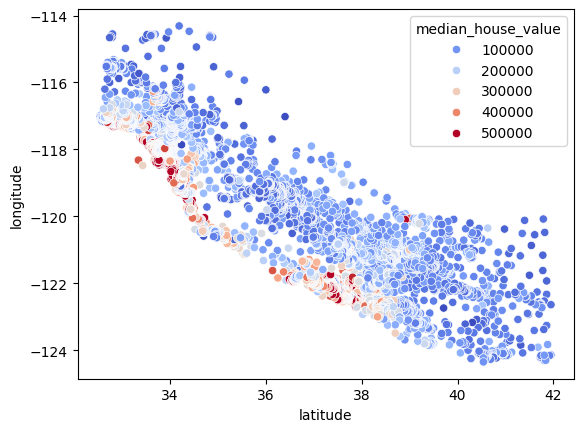

In [3]:
# 1.2 Ploteamos lo informacion que nos interesa en este caso
# la longuitud y latitud de las casas basados en el precio medio de las casas
import seaborn as sb
sb.scatterplot(x="latitude", y="longitude", data = datos, hue="median_house_value",
               palette="coolwarm")

<Axes: xlabel='latitude', ylabel='longitude'>

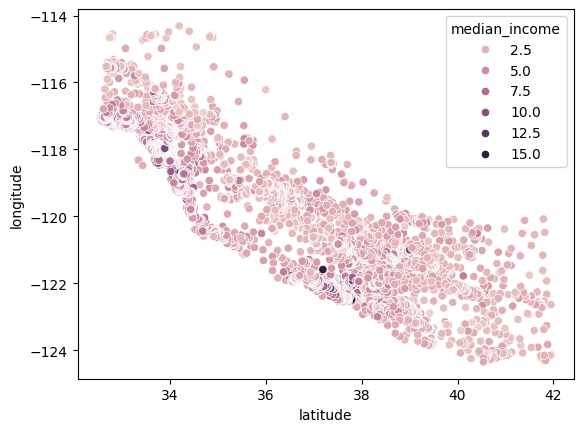

In [9]:
# 1.3 Ploteamos lo informacion que nos interesa en este caso
# la longuitud y latitud de las casas basados en los ingresos de las personas
import seaborn as sb
sb.scatterplot(x="latitude", y="longitude", data = datos, hue="median_income")

In [11]:
# 1.4 En el grafico anterior podemos ver que hay pocas personas con mayores ingresos
# Si queremos hacer una campania de publicidad, es mejor clasificar estos datos
# en 3 grupos. 

datos.loc[:, # este paramitro trae las filas -> desde la primero hasta la ultimo
          ["latitude","longitude","median_income"] # idicamos las columnas a utilizar
          ]

,latitude,longitude,median_income
0,37.88,-122.23,8.3252
1,37.86,-122.22,8.3014
2,37.85,-122.24,7.2574
3,37.85,-122.25,5.6431
4,37.85,-122.25,3.8462
...,...,...,...
20635,39.48,-121.09,1.5603
20636,39.49,-121.21,2.5568
20637,39.43,-121.22,1.7000
20638,39.43,-121.32,1.8672


In [14]:
# 1.5 Definimos nuestros modelo y los valores

X = datos.loc[:, # este paramitro trae las filas -> desde la primero hasta la ultimo
          ["latitude","longitude","median_income"] # idicamos las columnas a utilizar
          ]

# 2.- Preparamos nuestro medlo de K-Means con 3 Clusters

In [15]:
# 2.- Preparamos nuestro modelo y hacemos las predicciones con las
# columnas seleccionadas.
from sklearn.cluster import KMeans
modelo = KMeans(n_clusters=3)
predicciones = modelo.fit_predict(X) # En lugar de usar fit() , usamos fit_predict

In [18]:
# 2.1 Vemos el total de registros que trajo.
predicciones.shape

(20640,)

In [20]:
# 2.2 Agregamos la columna de predicciones a nuestro ddataFrame X
X["segmento_economico"] = predicciones
X

,latitude,longitude,median_income,segmento_economico
0,37.88,-122.23,8.3252,1
1,37.86,-122.22,8.3014,1
2,37.85,-122.24,7.2574,1
3,37.85,-122.25,5.6431,1
4,37.85,-122.25,3.8462,1
...,...,...,...,...
20635,39.48,-121.09,1.5603,1
20636,39.49,-121.21,2.5568,1
20637,39.43,-121.22,1.7000,1
20638,39.43,-121.32,1.8672,1


In [21]:
# 2.3 Vemos cuantos calleron en el segmento economico
X["segmento_economico"].value_counts()

segmento_economico
0    9763
1    8439
2    2438
Name: count, dtype: int64

<Axes: xlabel='latitude', ylabel='longitude'>

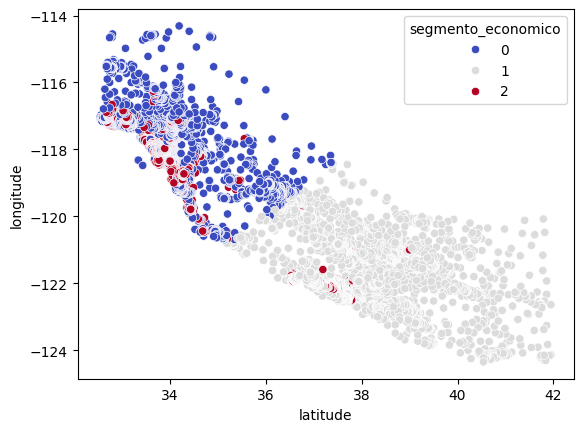

In [22]:
# 2.3 Ploteamos lo informacion que nos interesa en este caso
# la longuitud y latitud de las casas basados en el "segmento economico"
import seaborn as sb
sb.scatterplot(x="latitude", y="longitude", data = X, hue="segmento_economico",
               palette="coolwarm")

# NOTA: Lo que nos dice la grfica es cuantos clussters segmento en este caso 3
# como se habia definido en la linea de codigo arriba. 
# modelo = KMeans(n_clusters=3) , realizando este mismo ejercicio con 6

# 3.- Preparamos nuestro medlo de K-Means con 6 clusters

In [23]:
# 3.1- Preparamos nuestro modelo y hacemos las predicciones con las
# columnas seleccionadas.
from sklearn.cluster import KMeans
modelo = KMeans(n_clusters=6)
predicciones = modelo.fit_predict(X) # En lugar de usar fit() , usamos fit_predict

In [25]:
# 3.2 Agregamos la columna de predicciones a nuestro ddataFrame X
X["segmento_economico"] = predicciones
X

,latitude,longitude,median_income,segmento_economico
0,37.88,-122.23,8.3252,5
1,37.86,-122.22,8.3014,5
2,37.85,-122.24,7.2574,5
3,37.85,-122.25,5.6431,5
4,37.85,-122.25,3.8462,1
...,...,...,...,...
20635,39.48,-121.09,1.5603,1
20636,39.49,-121.21,2.5568,1
20637,39.43,-121.22,1.7000,1
20638,39.43,-121.32,1.8672,1


In [26]:
# 3.3 Vemos cuantos calleron en el segmento economico 
# vemos la impresion con 6 Clusters
X["segmento_economico"].value_counts()

segmento_economico
1    5543
4    4503
0    4460
5    2243
3    2234
2    1657
Name: count, dtype: int64

<Axes: xlabel='latitude', ylabel='longitude'>

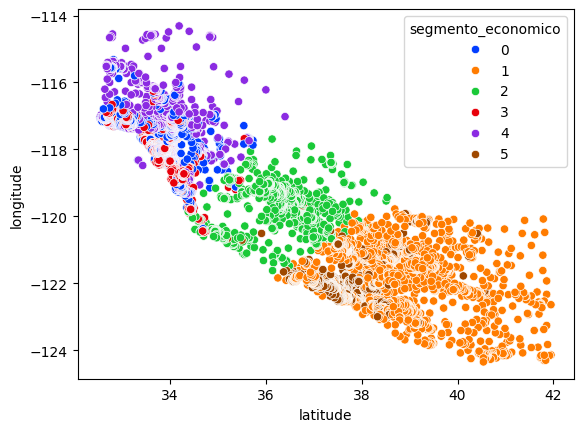

In [28]:
# 3.3 Ploteamos lo informacion que nos interesa en este caso
# la longuitud y latitud de las casas basados en el "segmento economico"
import seaborn as sb
sb.scatterplot(x="latitude", y="longitude", data = X, hue="segmento_economico",
               palette="bright")

# NOTA: Lo que nos dice la grfica es cuantos clussters segmento en este caso 3
# como se habia definido en la linea de codigo arriba. 
# modelo = KMeans(n_clusters=6) , 

# 4. Vemos algunas graficas para traer mas informacion

/tmp/ipykernel_21523/2596876751.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.countplot(x="segmento_economico",data=X,palette="bright")


<Axes: xlabel='segmento_economico', ylabel='count'>

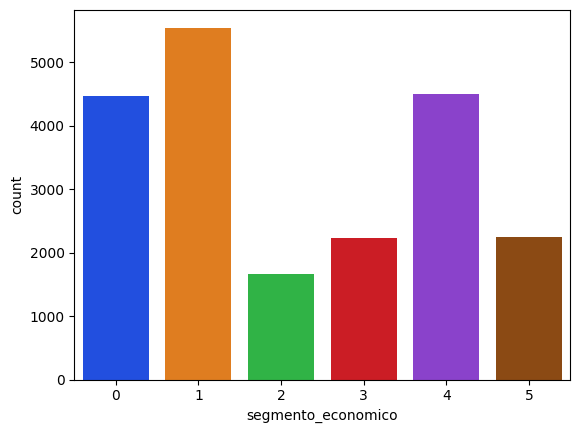

In [34]:
# 4.0 Vemos quienes son los que mas ganan, ya que en el la grafica anterior
# no se entiende mucho.
sb.countplot(x="segmento_economico",data=X,palette="bright")

In [33]:
X.groupby(["segmento_economico"])["median_income"].mean()

segmento_economico
0    4.151159
1    3.005732
2    2.656481
3    6.969260
4    2.394217
5    6.225337
Name: median_income, dtype: float64

In [ ]:
# NOTA : Lo que nos indico el groupBy fue que las personas que msa ganan
# son las del grupo 5 y 3 segun su media_income